# Unsupervised Learning: Cluster analysis and dimension reduction.

This notebook has two parts covering unsupervised learning, using the same dataset.

Firstly it does a k-means clustering analysis, that that uses principal component analysis (PCA).

Second, it looks in more depth at the PCA.

## 1. Overview

Today we learned about about clustering for unsupervised machine learning and the k-means algorithm in particular. For a user-specified number $k$ of clusters, k-means assigns data points to their nearest centroid, which is iteratively readjusted to the mean of each cluster and points reassigned until clusters don't change anymore (or not much anymore). 


In this notebook we will use k-means clustering to analyse the Breast Cancer Wisconsin (Diagnostic) Data Set - check out the description here: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data.

The data is in fact labelled - the column ```"diagnosis"``` takes values 'B' (benign) and 'M' (malignant). Here, we will ignore the outcome labels at first, perform clustering and then check if the assigned clusters make any sense, i.e. coincide with the observed outcomes. 

## 2. Import and data prep
### 2.1. Importing Dependencies

As usual, we start by importing libraries we will use later on. Throughout the notebook, if any functions are unclear, try googling the library and function to familiarize yourself with the functions and their in- and outputs. 

In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn import preprocessing
from subprocess import check_output
from sklearn.metrics import confusion_matrix, accuracy_score, silhouette_score, adjusted_rand_score

### 2.2. Load data

**TASK:** Load the file ```breast-cancer-wisconsin.csv```, located in the Datasets directory.

In [2]:
data = pd.read_csv('../Datasets/breast-cancer-wisconsin.csv')

### 2.3. Data summary

As usual, we start by having a look at the data. 

**TASK:** Use ```head()```, ```describe()``` and ```info()``` on the dataframe to get a first idea.

In [3]:
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
data.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

**TASK:** Check how many data points are classed as benign/malignant using ```groupby()``` and ```size()```, just as we did in the kNN notebook. 

In [6]:
data.groupby('diagnosis').size()

diagnosis
B    357
M    212
dtype: int64

**TASK:** Check for missing values (NaN = not a number) using ```isna()``` on the dataframe, just as we did in the regression notebook. 

In [7]:
data.isna().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

**TASK:** We don't need the first and last column ('id', 'Unnamed: 32') - drop them. 

In [8]:
# Cleaning and modifying the data
data = data.drop('id',axis=1)
data = data.drop('Unnamed: 32',axis=1)

**TASK:** Assign the number of data points and columns to variables ```ndat, nvar``` using ```shape```.

In [9]:
ndat, nvar = data.shape
ndat, nvar

(569, 31)

Last week, we discussed that machine learning algorithms actually run on a matrix of numbers, so we need to map non-numerical variables to numbers in order to run these algorithms.  

So, finally, we map the diagnostic values to binary 0/1 values. 

In [10]:
# Mapping Benign to 0 and Malignant to 1 
data['diagnosis'] = data['diagnosis'].map({'M':1,'B':0})

## 3. Exploratory Data Analysis

**TASK:** In the past two sessions, we've used a variety of plotting tools. Think which ones you found most useful and try them on this dataset. Keep in mind though, that this dataset has a lot more data columns than those we've used in the previous two sessions. This might make it a bit more cumbersome to look at all variables at once. 

Here is an example visualization using a pair plot. 

**Caution:** Plotting all data columns using ```sns.pairplot()``` takes a long time (~2 minutes on a MacBook Air or on Noteable)! It also looks overwhelming. If you'd like to have a quick look, choose just up to 5-10 columns (0: "diagnosis" should be included if you'd like to use it for ```hue```).

Elapsed time: 1.695203 seconds.



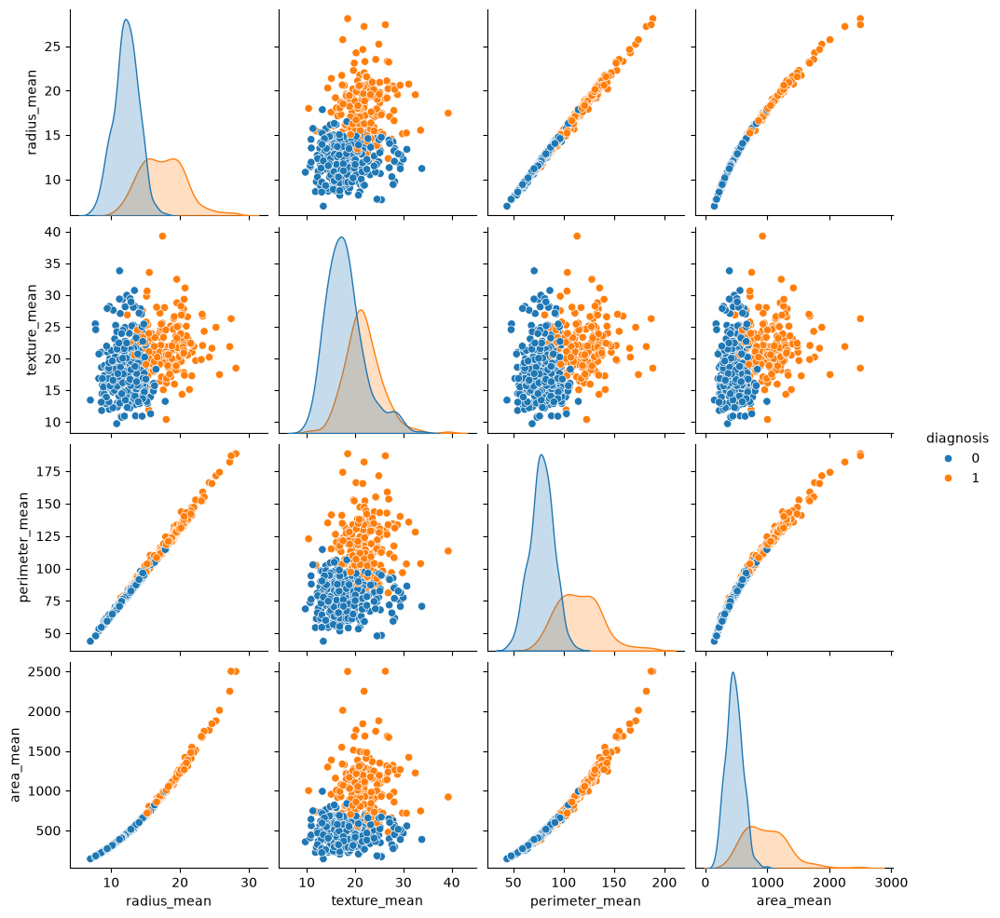

In [11]:
# the time library tracks how long code takes to run
import time
t = time.time()

# next line actually creates the pair plot
sns.pairplot(data.iloc[:,0:5], hue = "diagnosis")

# these lines report how long the code took
elapsedtime = time.time() - t
print( "Elapsed time: %f seconds.\n" %elapsedtime )


In [12]:
# the time library tracks how long code takes to run
import time
t = time.time()

# the next line actually creates the pair plot
sns.pairplot(data, hue = "diagnosis")

# these lines report how long the code took
elapsedtime = time.time() - t
print( "Elapsed time: %f seconds.\n" %elapsedtime )


Elapsed time: 98.966655 seconds.



**Reflect:** Do you think the data look well separable, i.e. a clustering method would be able to find clusters that roughly coincide with the diagnotic outcomes?

**TASK:** Compute and plot the correlation matrix, just as we did in the Class 10 homework notebook. Try to give this an informative title, and informative colourmap.

Text(0.5, 1.0, 'Correlation Heatmap for Breast Cancer dataset')

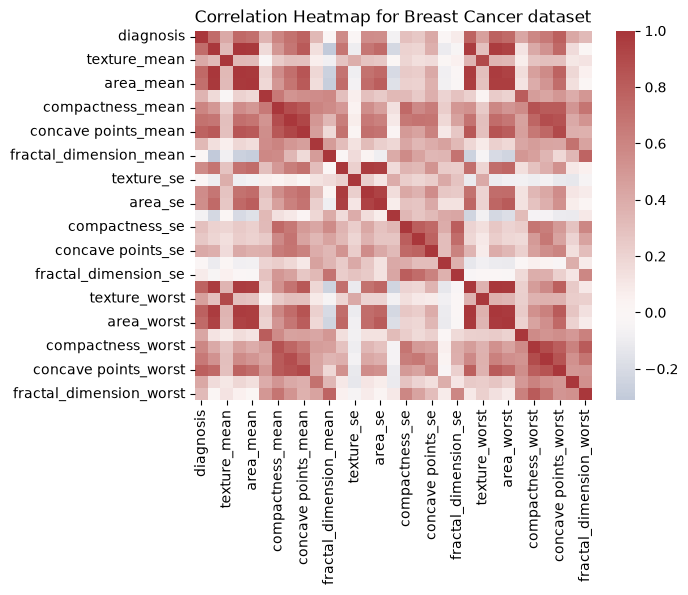

In [13]:
corr_matrix = data.corr()

fig = sns.heatmap(corr_matrix, center = 0, cmap = sns.color_palette("vlag", as_cmap=True))
fig.set_title('Correlation Heatmap for Breast Cancer dataset')

**Reflect**: what is this correlation heatmap telling you about the patterns in the data?

## 4. Data preparation
### 4.1. Data scaling

Data scaling is important, as we're assigning clusters based on Euclidean distance. This means that for all data variables to get the same importance, they need to range on the same scale. 

**TASK:** Scale the data using ```scale()``` from sklearn ```preprocessing``` library we imported at the beginning. Call the scaled data ```datas```, short for "data scaled". We don't need to rescale the ```"diagnosis"``` column, because we are not using this in the clustering.

In [14]:
# Scaling the dataset
datas = pd.DataFrame(preprocessing.scale(data.iloc[:,1:nvar+1]))
datas.columns = list(data.iloc[:,1:nvar+1].columns)
datas['diagnosis'] = data['diagnosis']

**TASK:** Assign the scaled data to a variable ```scaled_X```, which we will use for the cluster analysis. Don't forget to drop diagnosis, which we are not using in the clustering. 

In [15]:
# Creating the high dimensional feature space scaled_X
datas_nodiagnosis = datas.drop('diagnosis',axis=1)
scaled_X = datas_nodiagnosis.values
scaled_X

array([[ 1.09706398, -2.07333501,  1.26993369, ...,  2.29607613,
         2.75062224,  1.93701461],
       [ 1.82982061, -0.35363241,  1.68595471, ...,  1.0870843 ,
        -0.24388967,  0.28118999],
       [ 1.57988811,  0.45618695,  1.56650313, ...,  1.95500035,
         1.152255  ,  0.20139121],
       ...,
       [ 0.70228425,  2.0455738 ,  0.67267578, ...,  0.41406869,
        -1.10454895, -0.31840916],
       [ 1.83834103,  2.33645719,  1.98252415, ...,  2.28998549,
         1.91908301,  2.21963528],
       [-1.80840125,  1.22179204, -1.81438851, ..., -1.74506282,
        -0.04813821, -0.75120669]], shape=(569, 30))

### 4.2. Dimensionality reduction for later visualisation

We have 30 variables, and it is hard to visualize results in 30-D.

Here we use dimensionality reduction, to project data down to 2D and visualize clustering results later on.

#### 4.2.1. Principal component analysis

Principal component analysis (PCA) is a popular technique for analyzing large datasets containing a high number of dimensions/features per observation, increasing the interpretability of data while preserving the maximum amount of information, and enabling the visualization of multidimensional data.

Here we will apply PCA to the scaled data.

In [16]:
from sklearn.decomposition import PCA

pca = PCA()
#Fit PCA to the dataset (only variables, excluding class)
pca.fit(datas_nodiagnosis)

# datapca is the data projected onto the principle components
datapca = pca.transform(datas_nodiagnosis)
outcomes = data.diagnosis

In [17]:
outcomes

0      1
1      1
2      1
3      1
4      1
      ..
564    1
565    1
566    1
567    1
568    0
Name: diagnosis, Length: 569, dtype: int64

Next inspect the `datapca` object to see what it is. Be sure to check the shape and size of this, and compare it to the size of the data.

In fact, each **column** of this matrix is a principal component. We'll explain this more later.

In [18]:
datapca.shape

(569, 30)

In [19]:
data.shape

(569, 31)

In [20]:
datapca

array([[ 9.19283683e+00,  1.94858307e+00, -1.12316616e+00, ...,
         3.39144536e-02, -4.56477199e-02,  4.71692081e-02],
       [ 2.38780180e+00, -3.76817174e+00, -5.29292687e-01, ...,
        -3.26241827e-02,  5.68742432e-03,  1.86787626e-03],
       [ 5.73389628e+00, -1.07517380e+00, -5.51747593e-01, ...,
        -4.70258247e-02, -3.14589659e-03, -7.50534755e-04],
       ...,
       [ 1.25617928e+00, -1.90229671e+00,  5.62730526e-01, ...,
         2.57775589e-03, -6.70621179e-03, -3.77041667e-03],
       [ 1.03747941e+01,  1.67201011e+00, -1.87702933e+00, ...,
         6.80863833e-02,  8.41632764e-02,  2.37828222e-02],
       [-5.47524330e+00, -6.70636791e-01,  1.49044308e+00, ...,
         9.51587894e-03,  6.09131090e-02,  1.94755854e-02]],
      shape=(569, 30))

## 5. Cluster analysis

### 5.1. Perform k-means clustering

At last, we can use k-means to cluster our dataset. 

**TASK:** Create a k-means model object called ```km``` using ```KMeans()``` and then fit it using ```fit_predict()``` on the data vector ```datas_nodiagnosis```. Use 2 clusters.

In [21]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=2, init='k-means++', 
            n_init=10, max_iter=300, tol=0.0001, 
            verbose=0, random_state=0, copy_x=True)
kY = km.fit_predict(datas_nodiagnosis)

In [22]:
# Always inspect your objects! What is this telling you?
kY

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,

### 5.2. Cluster visualisation


#### 5.2.1 A small example of cluster visualisation

First let's use just the first two variables in the original dataset: radius_mean, and texture_mean. You already plotted these in the pairplot above.

**TASK:** Make two scatter plots of texture_mean against radius_mean. One should be coloured by the kNN cluster prediction `kY`, and the other by actual diagnosis `diagnosis

<Axes: xlabel='radius_mean', ylabel='texture_mean'>

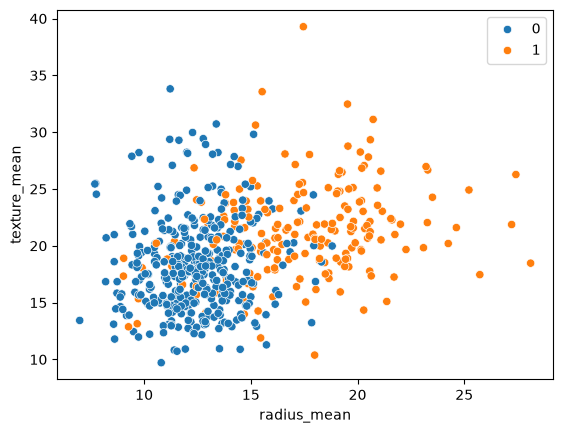

In [23]:
sns.scatterplot(x = data["radius_mean"], y = data["texture_mean"], hue = kY)

<Axes: xlabel='radius_mean', ylabel='texture_mean'>

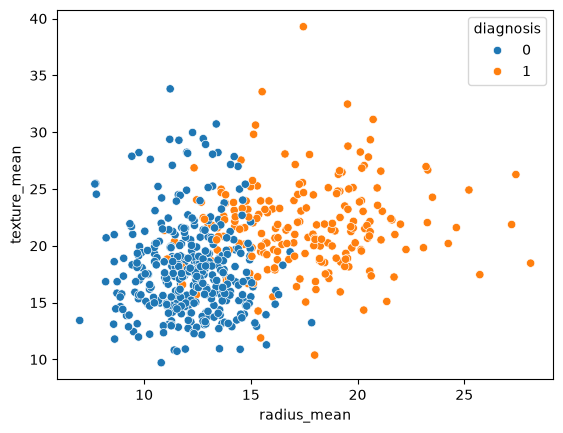

In [24]:
sns.scatterplot(x = data["radius_mean"], y = data["texture_mean"], hue = data["diagnosis"])

Compare these - do the clusters correspond to the diagnosis?

However, we have 30 variables in the dataset, and this only views the clusters in 2 of those variables. It's time to think ahead to the dimension reduction methods.

#### 5.2.2 Cluster visualisation and dimension reduction

Earlier in **§4** we computed the principal components. Use it now to visualize your clustering results in 2D. What does this 2D projection show?

**TASK:** Make two scatter plots using the first two principal components (```datapca```) computed in **§4.2.1** as axes. In the first scatter plot colour the data points by their cluster labels ```kY```, and in the second plot, for comparison, use the actual outcomes. 

Text(0, 0.5, 'PC2')

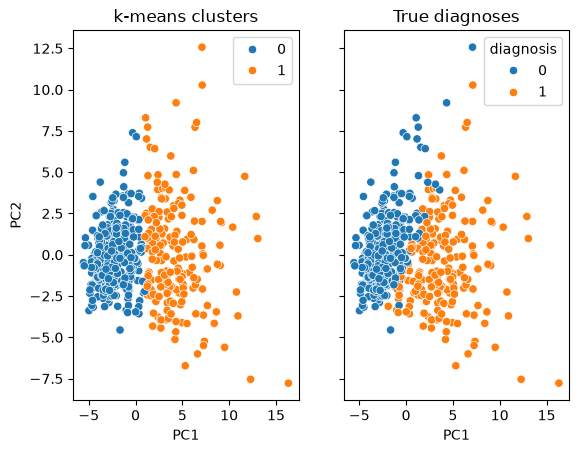

In [25]:
# this line allows us to make 2 plots next to each other
# look up the matplotlib library for subplots to learn more
fig, axes = plt.subplots(1, 2, sharey=True)

# create chart in first subplot axes[0]
sns.scatterplot(x=datapca[:,0], y=datapca[:,1], hue = kY, ax=axes[0])
#sns.boxplot(data=df, x='team', y='assists', ax=axes[0,1])
axes[0].set_title('k-means clusters')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# create chart in second subplot axes[1]
sns.scatterplot(x=datapca[:,0], y=datapca[:,1], hue = data['diagnosis'], ax=axes[1])
axes[1].set_title('True diagnoses')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')


**Reflect:** From the above plots, do you think the clustering did a good job? In which respects do the clusters resemble the true diagnosis, in which respects do they differ?

### 5.3. Evaluation

Since we know the actual outcomes, we can compare them to the assigned clusters. 


**TASK:** Compute the confusion matrix (like we did for kNN) and plot a heatmap of it (like we did in the regression notebook). 


 Clusters coincide with diagnosis with 90.51% accuracy.


array([[339,  18],
       [ 36, 176]])

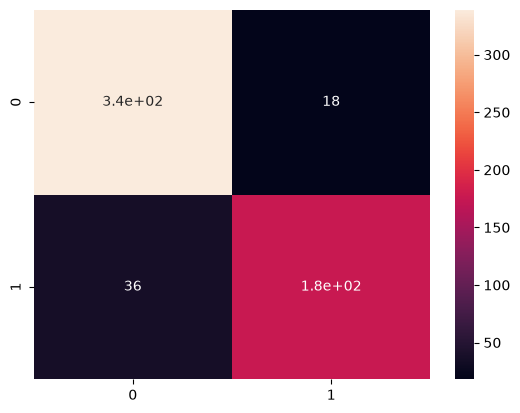

In [26]:
# The clustering doesn't know which class is which, so we might need to invert cluster indices (swap 0 and 1)
# kY = [int(x) for x in kY==0]
cm = confusion_matrix(outcomes, kY)
sns.heatmap(cm, annot=True)

accuracy = accuracy_score(data.diagnosis, kY)
print('\n Clusters coincide with diagnosis with ' + str(round(accuracy*100, 2)) + '% accuracy.')
cm

## 6. Finding a good $k$

Above, we used $k=2$, because we knew that there are two different diagnostic outcomes. In principle, however, when faced with a clustering problem, we don't *a priori* know the number of clusters. In the lecture, we learned that we can use an elbow plot to find the best $k$. 

**TASK:** Within a ```for``` loop, fit a k-means model for $k=1,...,10$ and compute the total within-cluster variation (**tip:** it can be accessed via the ```inertia_``` property of the fitted model). Store the within-cluster variation in an array.

In [27]:
# wcss is short for "within-cluster-sum-of-squares"
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', 
                    n_init=10, max_iter=300, tol=0.0001, 
                    verbose=0, random_state=0, copy_x=True)
    kmeans.fit(datas_nodiagnosis)
    wcss.append(kmeans.inertia_)

wcss

[17069.999999999993,
 11595.526607115773,
 10061.797818243693,
 9330.178466761789,
 8556.186600060944,
 7966.5090460914225,
 7535.730028936457,
 7220.020648074173,
 7000.533305185064,
 6615.95270888165]

**TASK:** Plot this within-cluster sum of squares against the number of clusters, $k$, to get the elbow plot. What does the plot say about the optimal value of $k$?

Text(0, 0.5, 'WCSS')

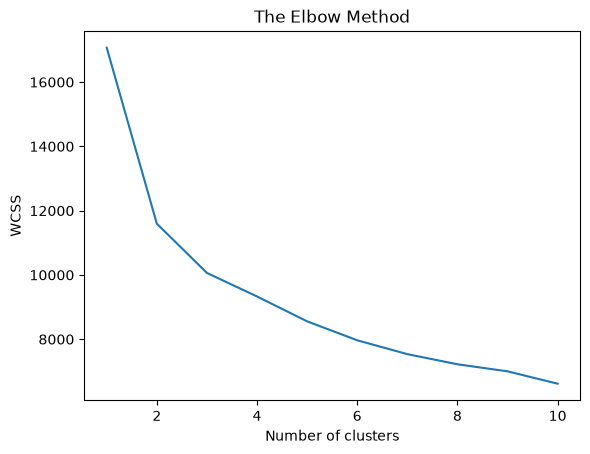

In [28]:
sns.lineplot(x = range(1,11), y = wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')


## 6. Correlation and covariance data analysis

**TASK:** Check again the correlation matrix of the data, that we looked at above.

Now we could check out the covariance matrix of the data or its scaled version as we heard in the lecture that they have something to do with the PCA projection. How do the correlation matrix and the covariance matrix relate to each other?

Text(0.5, 1.0, 'Correlation Matrix Heatmap for Breast Cancer dataset')

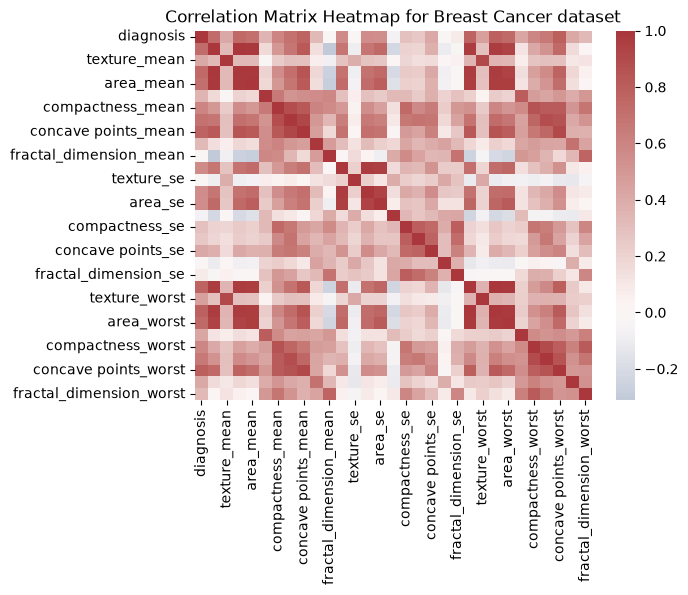

In [29]:
corr_matrix = data.corr()

fig = sns.heatmap(corr_matrix, center = 0, cmap = sns.color_palette("vlag", as_cmap=True))
fig.set_title('Correlation Matrix Heatmap for Breast Cancer dataset')

**TIP:** To calculate covariance, use the `cov` function from pandas.

Text(0.5, 1.0, 'Covariation Matrix Heatmap for Breast Cancer dataset')

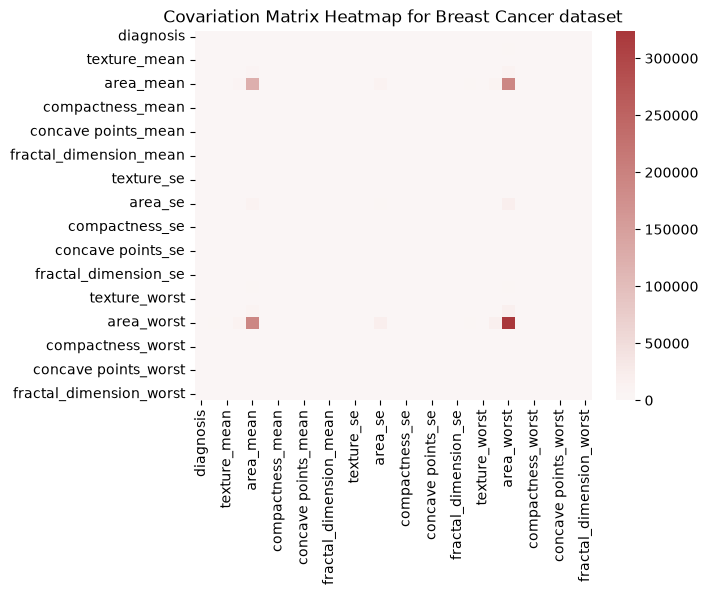

In [30]:
cov_matrix = data.cov()

fig = sns.heatmap(cov_matrix, center = 0, cmap = sns.color_palette("vlag", as_cmap=True))
fig.set_title('Covariation Matrix Heatmap for Breast Cancer dataset')

To clarify what's happening here - the covariance matrix is essentially working on the scaled data. Correlation is like covariance, but scaled by variance. The difference between the informative correlation heatmap and the less informative covariance heatmap is an example of how data scaling helps us to see patterns in the data.

### 6.1. For the mathematically curious

Optional - Using the ```linalg``` library from numpy, compute the eigenvalues of the above covariance matrix. Create two bar plots of the unnormalized and normalized eigenvalues (i.e. divided by the sum of eigenvalues). We can check later if they coincide with the explained variances by the PC's.

**TIP:** convert the covariance matrix to an array first, before feeding it to the linalg library, using the function `to_numpy`.

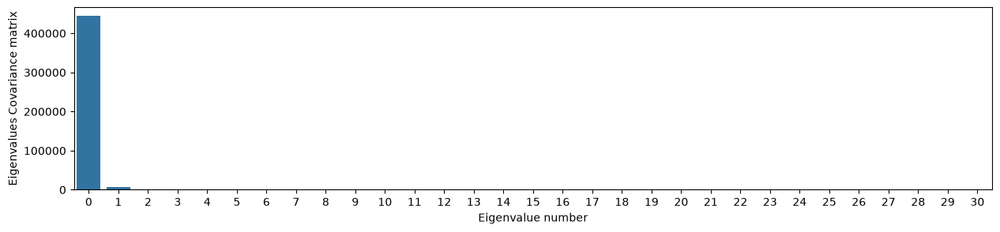

In [31]:
from numpy import linalg

eigenvalues, eigenvectors = linalg.eig(cov_matrix)

df_ev = pd.DataFrame({'Eigenvalues Covariance matrix': eigenvalues,
                      'Normalized eigenvalues': eigenvalues / np.sum(eigenvalues),
                      'Eigenvalue number' : range(len(eigenvalues))})

plt.figure(figsize = (15,3))
sns.barplot(x = 'Eigenvalue number', y = 'Eigenvalues Covariance matrix', data = df_ev);

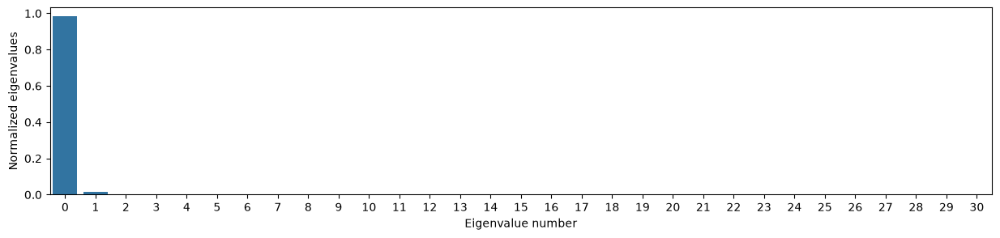

In [32]:
plt.figure(figsize = (15,3))
sns.barplot(x = 'Eigenvalue number',y = 'Normalized eigenvalues',data = df_ev);

## 7. Principal Component Analysis (PCA)

Now we will use PCA to find a linear projection of the variable space. As above, but looking more in depth at what PCA is doing.

First, we will look at the full PCA space to then decide how to reduce it. 

### 7.1. Full PCA

**TASK:** Create a PCA object called ```pca``` using ```decomposition.PCA()```, then transform the data into the PCA space by using ```fit_transform``` on ```scaled_X```. Check out the transformed data.

This is the same as above.

In [33]:
from sklearn.decomposition import PCA
pca = PCA()
tdata = pca.fit_transform(scaled_X)
tdata

array([[ 9.19283683e+00,  1.94858307e+00, -1.12316616e+00, ...,
         3.39144536e-02, -4.56477199e-02,  4.71692081e-02],
       [ 2.38780180e+00, -3.76817174e+00, -5.29292687e-01, ...,
        -3.26241827e-02,  5.68742432e-03,  1.86787626e-03],
       [ 5.73389628e+00, -1.07517380e+00, -5.51747593e-01, ...,
        -4.70258247e-02, -3.14589659e-03, -7.50534755e-04],
       ...,
       [ 1.25617928e+00, -1.90229671e+00,  5.62730526e-01, ...,
         2.57775589e-03, -6.70621179e-03, -3.77041667e-03],
       [ 1.03747941e+01,  1.67201011e+00, -1.87702933e+00, ...,
         6.80863833e-02,  8.41632764e-02,  2.37828222e-02],
       [-5.47524330e+00, -6.70636791e-01,  1.49044308e+00, ...,
         9.51587894e-03,  6.09131090e-02,  1.94755854e-02]],
      shape=(569, 30))

**Reflect:** Have the dimensions been reduced? What is the new transformed data?

We can see above that the dimensions after PCA have not reduced. We've got entire set of new features projected onto the principal componenets. We have to find which or if all components are actualy important. 

### 7.2. Analysis of the PCA space

**TASK:** Check out the ```explained_variance_``` and ```explained_variance_ratio_``` attributes of the pca object. Create bar plots of them and compare to the bar plots of the eigenvalue

In [34]:
#Information content by all new indep variables
pca.explained_variance_ratio_

array([4.42720256e-01, 1.89711820e-01, 9.39316326e-02, 6.60213492e-02,
       5.49576849e-02, 4.02452204e-02, 2.25073371e-02, 1.58872380e-02,
       1.38964937e-02, 1.16897819e-02, 9.79718988e-03, 8.70537901e-03,
       8.04524987e-03, 5.23365745e-03, 3.13783217e-03, 2.66209337e-03,
       1.97996793e-03, 1.75395945e-03, 1.64925306e-03, 1.03864675e-03,
       9.99096464e-04, 9.14646751e-04, 8.11361259e-04, 6.01833567e-04,
       5.16042379e-04, 2.72587995e-04, 2.30015463e-04, 5.29779290e-05,
       2.49601032e-05, 4.43482743e-06])

**TASK:** Make a scree plot / elbow plot based on the ```explained_variance_ratio_```. Is there a clear scree point / elbow?

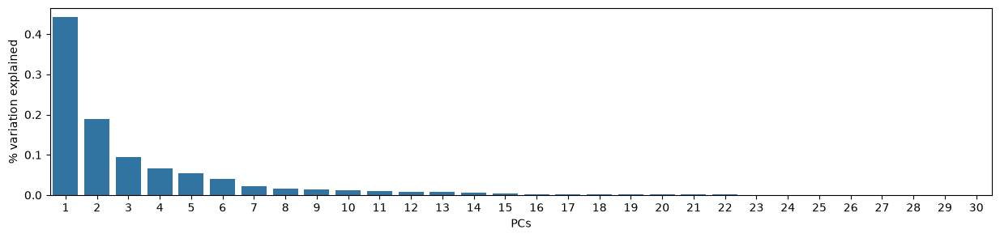

In [35]:
df_expvar = pd.DataFrame({'% variation explained': pca.explained_variance_ratio_,
                          'PCs': range(1,nvar)})

plt.figure(figsize = (15,3))
sns.barplot(x = 'PCs',y = '% variation explained',data = df_expvar);

**TASK:** Now plot the cumulative explained variance ratios using ```np.comsum()```. Do you find this or the scree plot more informative?

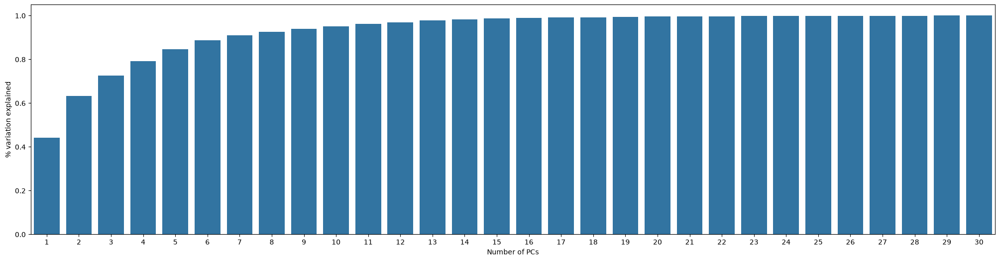

In [36]:
df_cexpvar = pd.DataFrame({'% variation explained': np.cumsum(pca.explained_variance_ratio_),
                    'Number of PCs': range(1,nvar)})

plt.figure(figsize = (25,6))
sns.barplot(x = 'Number of PCs',y = '% variation explained',data = df_cexpvar);

**Reflect:** Look at the scree and the cumulative plots. How many components are required to explain at least 80% of the variance in the data?

We can see that over 80% of information is explained by the first five components. 

**Optional TASK:** If you checked out the eigenvalues of the covariance matrix in the optional task in **§3.1**, now check out the ```explained_variance_``` attribute of our pca object. Make a plot and compare both this and the scree plot to those in **§3.1**. How do they relate to each other?

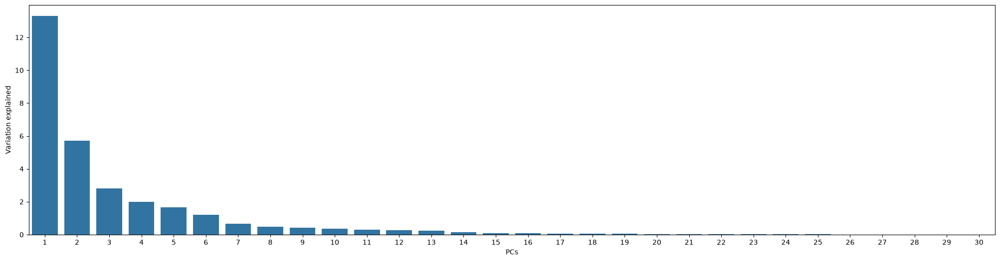

In [37]:
df_expvar2 = pd.DataFrame({'Variation explained':pca.explained_variance_,
                    'PCs':range(1,nvar)})

plt.figure(figsize = (25,6))
sns.barplot(x = 'PCs',y = 'Variation explained',data = df_expvar2);

### 7.4. Reduced PCA


Above, we learned that 5 components are required to explain at least 80% of the variance in our data. Let's now do dimension reduction by only looking at the first 5 components. 

**TASK:** Again using ```decomposition.PCA()``` now compute a PCA projection of the data setting ```n_components=5```. Then transform ```scaled_X``` into the reduced PCA space and store in ```pca_5var```.

In [38]:
#we will do PCA with only 5 components now as they seem to provide 80% of the information.
pca_red = PCA(n_components=5)
pca_5var = pca_red.fit_transform(scaled_X)

In [39]:
pca_5var.shape

(569, 5)

**TASK:** Check out ```explained_variance_``` and its sum to make sure we really explained at least 80% of our data variance.

In [40]:
pca_red.explained_variance_

array([13.30499079,  5.7013746 ,  2.82291016,  1.98412752,  1.65163324])

In [41]:
np.sum(pca_red.explained_variance_ratio_)*100

np.float64(84.73427431680723)

We can see that over 80% information is obtained in first 5 components.

**TASK:** Create a dataframe ```X_5PCs``` from the transformed data using ```pd.DataFrame()``` on the transformed data, i.e. using ```columns=['PC1','PC2','PC3','PC4','PC5']``` of ```pca_5var```. Check it out using ```head()```.

In [42]:
X_5PCs = pd.DataFrame(pca_5var,columns=['PC1','PC2','PC3','PC4','PC5'])
X_5PCs.head()

,PC1,PC2,PC3,PC4,PC5
0,9.192837,1.948583,-1.123166,-3.633731,1.195110
1,2.387802,-3.768172,-0.529293,-1.118264,-0.621775
2,5.733896,-1.075174,-0.551748,-0.912083,0.177086
3,7.122953,10.275589,-3.232790,-0.152547,2.960878
4,3.935302,-1.948072,1.389767,-2.940639,-0.546747


**TASK:** In the lecture, we learned that PCA makes a rotated projection of the data, where correlations have been removed. Check if that's true.

In [43]:
X_5PCs.corr()

,PC1,PC2,PC3,PC4,PC5
PC1,1.000000e+00,-4.615008e-16,-7.654509e-18,4.260768e-18,3.410760e-17
PC2,-4.615008e-16,1.000000e+00,1.490888e-17,-9.275134e-17,-1.193990e-16
PC3,-7.654509e-18,1.490888e-17,1.000000e+00,1.063762e-16,-2.359016e-16
PC4,4.260768e-18,-9.275134e-17,1.063762e-16,1.000000e+00,2.060149e-16
PC5,3.410760e-17,-1.193990e-16,-2.359016e-16,2.060149e-16,1.000000e+00


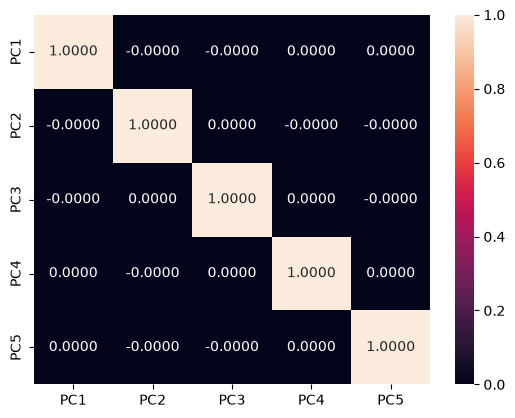

In [44]:
sns.heatmap(X_5PCs.corr(), annot= True, fmt='.4f');


We can see that there is no correlation among the principal components which is very important. 

## 8. Classification of the breast cancer data

### 8.1. On the reduced PCA space

We will now train LogisticRegression on the data projected onto the 5 principal components.

**Reflect:** Why would we choose logistic regression on this data? 

Logistic regression is a classification method for binary outcome data.

**TASK:** Use ```train_test_split()``` on ```X_5PCs``` and ```data.diagnosis``` to create a test-train data split with ```test_size=0.2``` and setting ```random_state``` to any number of your choice.

In [45]:
from sklearn.model_selection import train_test_split
X_5PCs_train, X_5PCs_test, y_train, y_test = train_test_split(X_5PCs, data.diagnosis, test_size = 0.2, random_state = 42)

**TASK:** Create a model called ```logreg``` using ```LogisticRegression()``` (from `sklearn.linear_model`). Set the parameter ```solver='lbfgs'```. Fit the model on the training data using ```fit()``` and then make predictions on the test set using ```predict()``` on the logreg model. 

In [46]:
from sklearn.linear_model import LogisticRegression

# create logreg model
logreg = LogisticRegression(solver='lbfgs')
# fit on training data
logreg.fit(X_5PCs_train, y_train)
# predict on test data
y_pred_test = logreg.predict(X_5PCs_test)

**TASK:** Print the confusion matrix and the accuracy of the logreg model using ```confusion_matrix()``` and ```accuracy_score()``` on the test data.

In [47]:
print('Confusion matrix:')
print(confusion_matrix(y_test,y_pred_test))
print()
print('Using logistic regression on the reduced PCA space, we get an accuracy of ' + str(round(accuracy_score(y_test,y_pred_test)*100, 2)) + '%.')

Confusion matrix:
[[70  1]
 [ 1 42]]

Using logistic regression on the reduced PCA space, we get an accuracy of 98.25%.


### 8.2. On the original data space

Now let's see how the regression on the reduced PCA space compares to regression on the original data space. 

**TASK:** Use ```train_test_split()``` on ```X``` and ```data.diagnosis``` to create a test-train data split with ```test_size=0.2``` and setting ```random_state``` to any number of your choice.

In [48]:
#let's compare Logistic Regession without PCA when we have all of the original features
X_train, X_test, y_train, y_test = train_test_split(scaled_X, data.diagnosis, test_size = 0.2, random_state = 42)

**TASK:** Create a model called ```logreg2``` using ```LogisticRegression()``` and setting ```solver='lbfgs'```. Fit the model on the training data using ```fit()``` and then make predictions on the test set using ```predict()``` on the ```logreg2``` model. 

In [49]:
# create logreg model
logreg2 = LogisticRegression(solver='lbfgs')
# fit on training data, all variables 
logreg2.fit(X_train, y_train)

# predict on test data
y_pred_test2 = logreg2.predict(X_test)
# ignore the warning

**TASK:** Print the confusion matrix and the accuracy of the logreg2 model using ```confusion_matrix()``` and ```accuracy_score()``` on the test data.

In [50]:
print('Confusion matrix:')
print(confusion_matrix(y_test,y_pred_test2))
print()
print('Using logistic regression on the original space, we get an accuracy of ' + str(round(accuracy_score(y_test,y_pred_test2)*100, 2)) + '%.')

Confusion matrix:
[[70  1]
 [ 2 41]]

Using logistic regression on the original space, we get an accuracy of 97.37%.


**TASK:** Compare the accuracy we got for classification when using the original data and when it's been projected onto the reduced PCA space. 

Accuracy is already high without PCA, but we can see that we gain accuracy when PCA is used compared to when it is not used. Since correlation has been removed from the data, the classifier has an easier task. 

**Optional TASK:** Can we get even better classification results by using more principal components?

### 8.3. Visualizing the classification results

Let's visualize the classification results on the whole data set.

**TASK:** First make predictions from the logreg models fitted on the reduced PCA and the original space, i.e. ```logreg``` and ```logreg2```, this time on the whole dataset, i.e. on ```X_5PCs``` and ```X```, respectively.

In [51]:
y_pred_all = logreg.predict(X_5PCs)
y_pred_all2 = logreg2.predict(scaled_X)

**TASK:** Make 3 scatter plots of the data projected onto the first two components, i.e. plotting ```X_5PCs.PC1``` vs ```X_5PCs.PC2```, and colour the points by 
1. Predictions from classification on the reduced PCA space.
2. Predictions from classification on the original data space.
3. True diagnoses.

Text(0, 0.5, 'PC2')

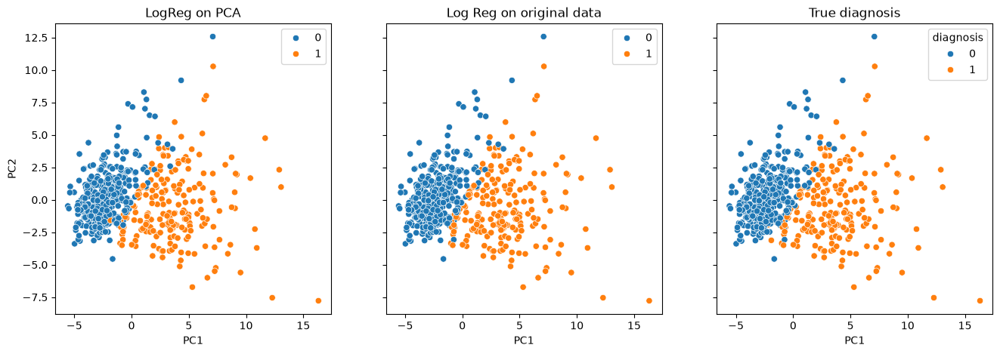

In [52]:
# this line allows us to make 3 plots next to each other
# and adjusts figure size to work for 3 plots
# look up the matplotlib library for subplots to learn more
f, axes = plt.subplots(1, 3, sharey=True, figsize = (16,5))

# create chart in first subplot axes[0]
sns.scatterplot(x=X_5PCs.PC1, y=X_5PCs.PC2, hue = y_pred_all, ax=axes[0])
axes[0].set_title('LogReg on PCA')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# create chart in second subplot axes[1]
sns.scatterplot(x=X_5PCs.PC1, y=X_5PCs.PC2, hue = y_pred_all2, ax=axes[1])
axes[1].set_title('Log Reg on original data')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

# create chart in third subplot axes[2]
sns.scatterplot(x=X_5PCs.PC1, y=X_5PCs.PC2, hue = data['diagnosis'], ax=axes[2])
axes[2].set_title('True diagnosis')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')


Since accuracy is quite high for both classifiers, both predictors are very close to the true diagnoses. We know however that we main some accuracy gains, and we can keep in mind next time we do classification and achieve low accuracy that PCA or dimension reduction, more generally, can help us improve predictions. 

#### Final points

This notebook has been adapted from: https://www.kaggle.com/code/vishwaparekh/cluster-analysis-of-breast-cancer-dataset/notebook
and
https://www.kaggle.com/code/jyotiprasadpal/dimension-reduction-methods/notebook.